In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [12]:
df = pd.read_csv(r"R:\rana\rana\train.csv")

In [20]:
print('Database shape:',df.shape)
print('head:',df.head())
print('info:',df.info())

Database shape: (891, 12)
head:    PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373

In [21]:
print(df.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [22]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


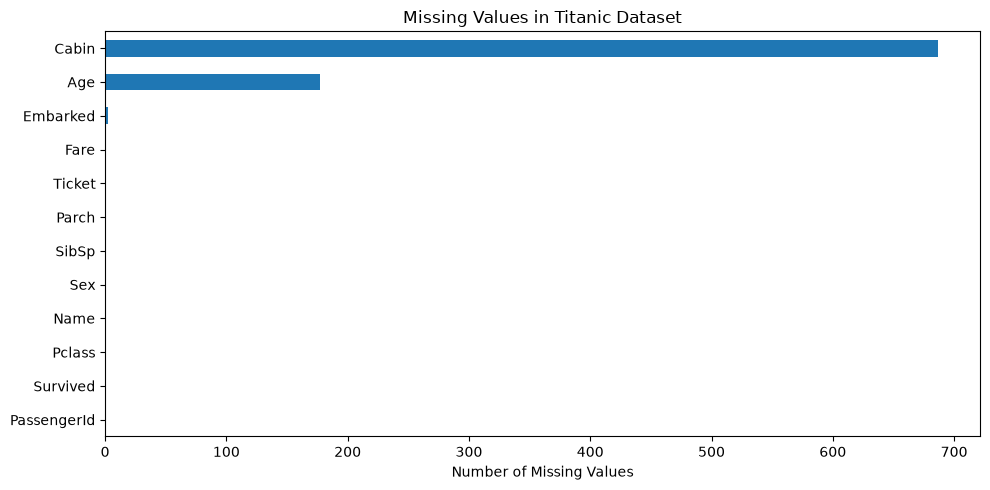

In [23]:
plt.figure(figsize=(10, 5))

df.isnull().sum().sort_values().plot(kind="barh")

plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Number of Missing Values")
plt.tight_layout()
plt.show()

Survived
0    549
1    342
Name: count, dtype: int64


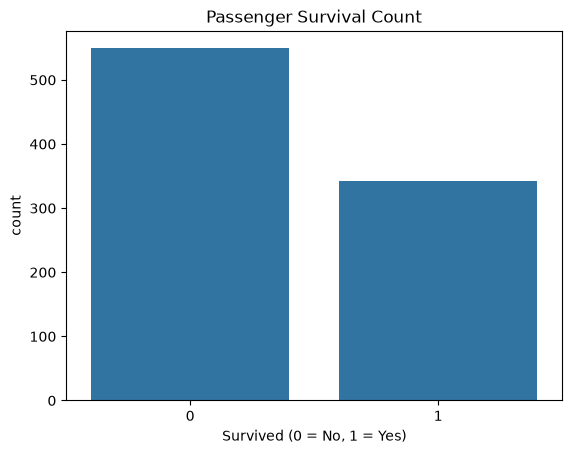

In [24]:
print(df["Survived"].value_counts())

sns.countplot(data=df, x="Survived")
plt.title("Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

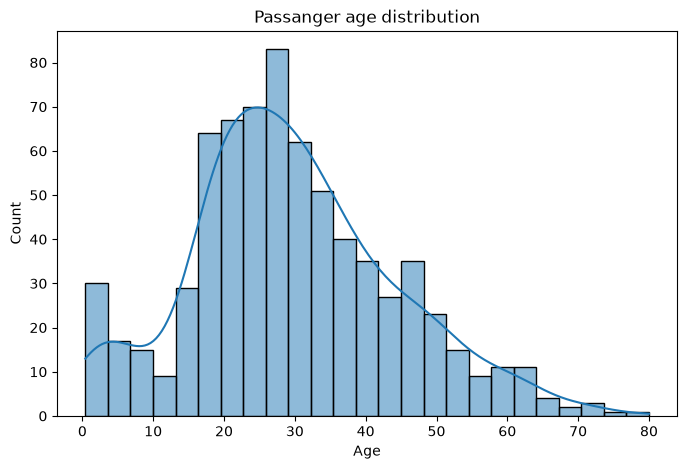

In [27]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Age", bins=25, kde=True)
plt.title('Passanger age distribution')
plt.xlabel('Age')
plt.show()

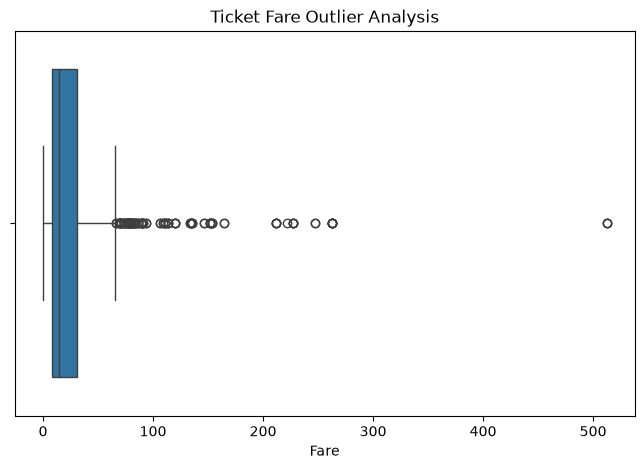

In [28]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Fare')

plt.title("Ticket Fare Outlier Analysis")
plt.show()

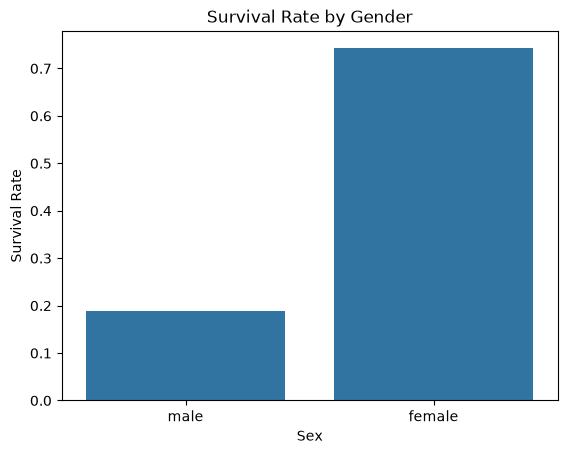

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


In [29]:
sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)

plt.title("Survival Rate by Gender")
plt.ylabel("Survival Rate")
plt.show()

print(df.groupby("Sex")["Survived"].mean() * 100)

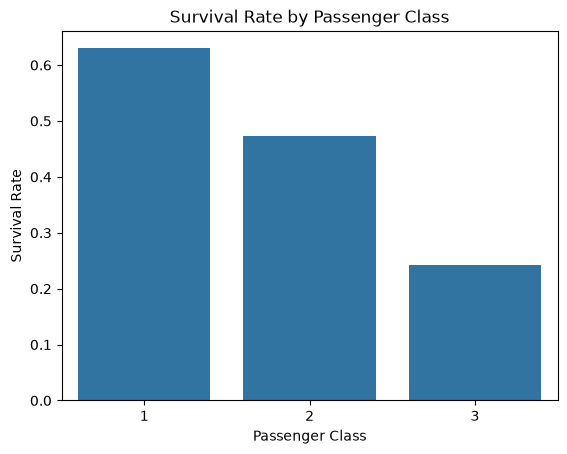

In [30]:
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

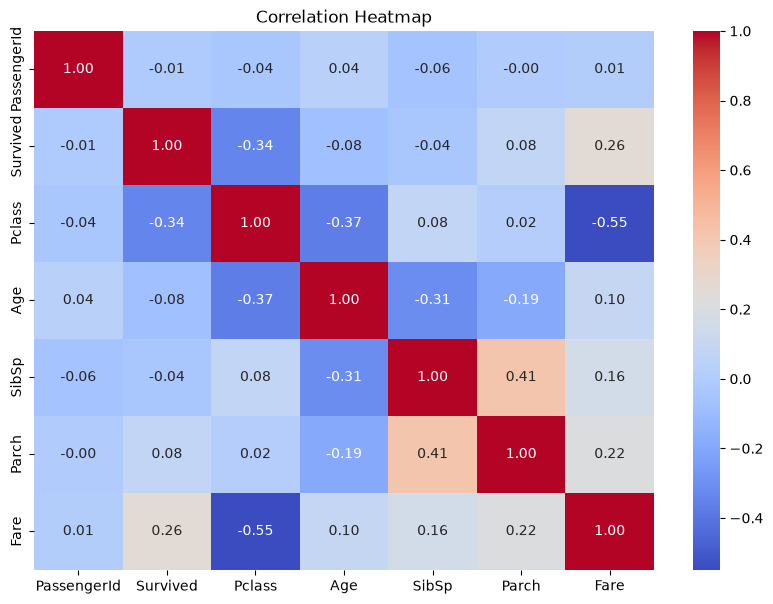

In [31]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

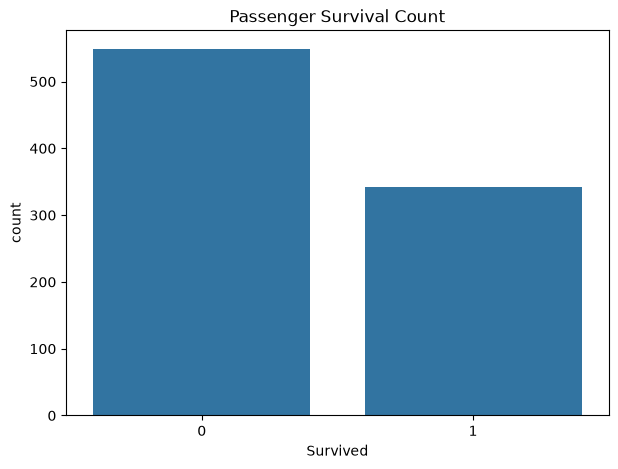

In [32]:
import os

os.makedirs("visualizations", exist_ok=True)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Survived")
plt.title("Passenger Survival Count")
plt.savefig("visualizations/survival_count.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [33]:
print("TOTAL PASSENGERS:", len(df))
print("TOTAL SURVIVORS:", df["Survived"].sum())

print("SURVIVAL RATE:",
      round(df["Survived"].mean() * 100, 2), "%")

print("\nMissing values:")
print(df.isnull().sum())

print("\nEDA completed successfully!")

TOTAL PASSENGERS: 891
TOTAL SURVIVORS: 342
SURVIVAL RATE: 38.38 %

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

EDA completed successfully!
